# Customer Segmentation Using Clustering
### Google Colab Demo — K-Means, Hierarchical Clustering & DBSCAN

**Purpose:** Run this notebook alongside the YouTube slides.  
The notebook is intentionally simple so the focus stays on the concepts and business interpretation.

**Dataset:** Mall Customers — using **Annual Income** and **Spending Score** for the main 2-D demonstration.

> Suggested recording flow: explain one slide → switch to Colab → run the related cell → return to the slides.

## 1. The Problem
We want to discover groups of customers with similar behaviour **without predefined labels**.

In [ ]:
# Import the basic libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

from scipy.cluster.hierarchy import dendrogram, linkage

plt.rcParams["figure.figsize"] = (7, 5)


## 2. Load the Customer Data
For this demo, we use the Mall Customers dataset.

In [ ]:
# Load the dataset directly in Colab

url = "https://raw.githubusercontent.com/sharmaroshan/Clustering-of-Mall-Customers/master/Mall_Customers.csv"

df = pd.read_csv(url)

print("Shape:", df.shape)
df.head()


Shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Explore the Data
First, identify the columns and decide which information should actually be used for clustering.

In [ ]:
# Quick inspection

print(df.columns.tolist())
print()
df.info()


['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
# Look at the numerical columns

df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


### Feature selection

For this simple visual demonstration, we use:

- **Annual Income (k$)**
- **Spending Score (1–100)**

We do not use customer ID or name because those are identifiers, not behavioural features.

In [ ]:
# Select the two features used in the demo

features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

X.head()


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


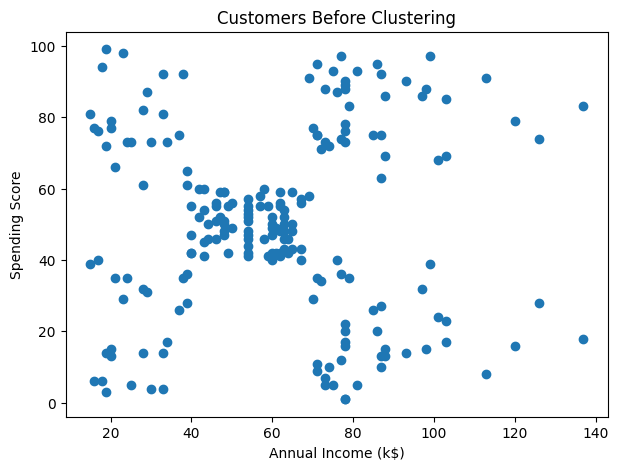

In [ ]:
# Visualize the raw customer data

plt.scatter(X[features[0]], X[features[1]])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Customers Before Clustering")
plt.show()


## 4. Scale the Features

Income and spending score are measured on different numerical scales.  
Standardization puts them on a comparable scale before distance-based clustering.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("First five scaled rows:")
print(X_scaled[:5])


First five scaled rows:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


# 5. K-Means

K-Means needs us to choose the number of clusters **K**.

We will use the **Elbow Method** first.

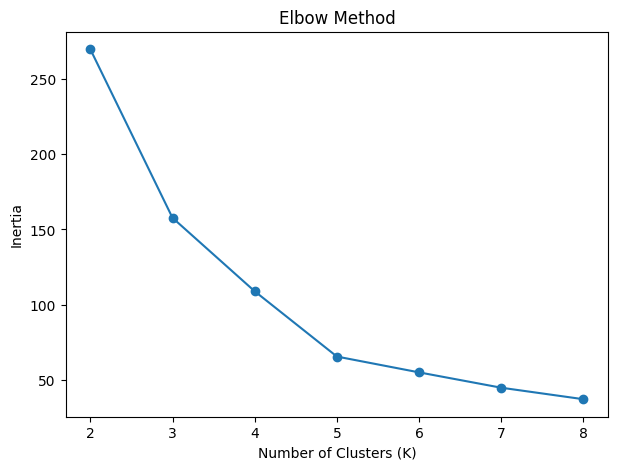

In [ ]:
# Elbow method

inertias = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(range(2, 9), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


### Fit K-Means with K = 3
For this demonstration, we will use three customer segments.

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

df[["CustomerID", "Annual Income (k$)", "Spending Score (1-100)", "KMeans_Cluster"]].head()


,CustomerID,Annual Income (k$),Spending Score (1-100),KMeans_Cluster
0,1,15,39,4
1,2,15,81,2
2,3,16,6,4
3,4,16,77,2
4,5,17,40,4


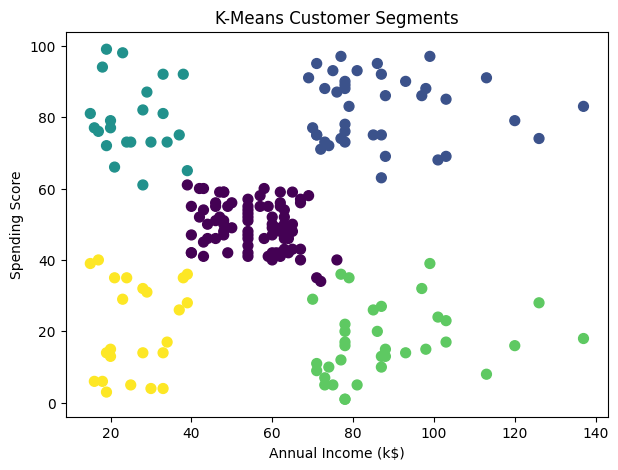

In [ ]:
# Plot the K-Means clusters

plt.scatter(
    X[features[0]],
    X[features[1]],
    c=df["KMeans_Cluster"],
    s=50
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Segments")
plt.show()


## 6. Profile the Segments

A cluster number such as 0, 1 or 2 has **no business meaning by itself**.

We need to calculate averages and translate the numerical groups into business descriptions.

In [ ]:
# Profile the K-Means clusters

profile = (
    df.groupby("KMeans_Cluster")[features]
      .mean()
      .round(2)
)

profile


,Annual Income (k$),Spending Score (1-100)
KMeans_Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


## 7. Hierarchical Clustering

Unlike K-Means, hierarchical clustering builds a tree of relationships.

The dendrogram helps us visualize where a possible cut can be made.

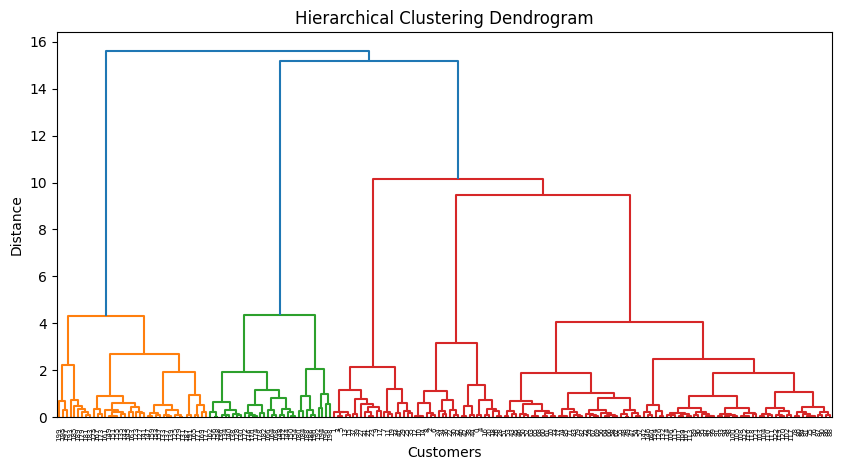

In [ ]:
# Build the hierarchical clustering tree

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()


In [ ]:
# Cut the hierarchy into 5 clusters

hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

df[["CustomerID", "Hierarchical_Cluster"]].head()


,CustomerID,Hierarchical_Cluster
0,1,4
1,2,3
2,3,4
3,4,3
4,5,4


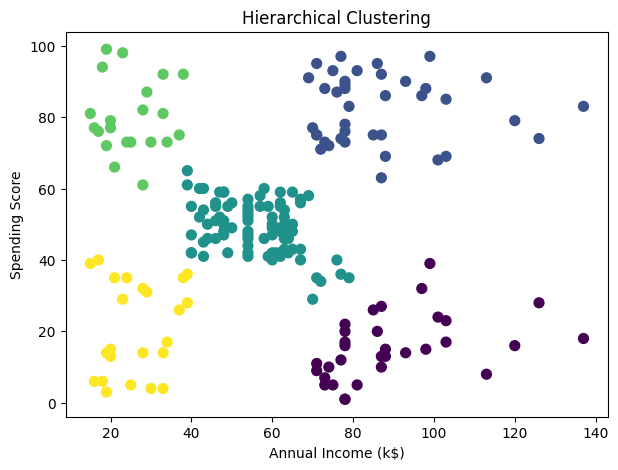

In [ ]:
# Visualize hierarchical clusters

plt.scatter(
    X[features[0]],
    X[features[1]],
    c=df["Hierarchical_Cluster"],
    s=50
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Hierarchical Clustering")
plt.show()


## 8. DBSCAN

DBSCAN does not require us to specify the number of clusters beforehand.

It groups dense regions and can mark isolated observations as **noise (-1)**.

Two important parameters:

- `eps` — neighbourhood radius
- `min_samples` — minimum points needed to form a dense region

In [ ]:
# Fit DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

df[["CustomerID", "DBSCAN_Cluster"]].head()


,CustomerID,DBSCAN_Cluster
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


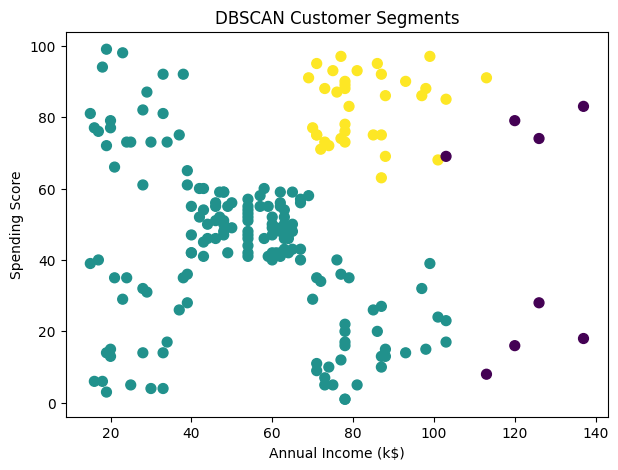

Cluster labels found: [np.int64(-1), np.int64(0), np.int64(1)]


In [ ]:
# Visualize DBSCAN results

plt.scatter(
    X[features[0]],
    X[features[1]],
    c=df["DBSCAN_Cluster"],
    s=50
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("DBSCAN Customer Segments")
plt.show()

print("Cluster labels found:", sorted(df["DBSCAN_Cluster"].unique()))


## 9. Evaluate Cluster Quality

We will compare the **internal structure** of the clusters using:

- **Silhouette Score:** higher is generally better
- **Davies–Bouldin Index:** lower is generally better
- **Calinski–Harabasz Index:** higher is generally better

These metrics describe mathematical structure. They do **not** automatically prove business usefulness.

In [ ]:
def evaluate_clusters(X_data, labels, model_name):
    # Ignore DBSCAN noise points when calculating these metrics
    mask = labels != -1

    X_eval = X_data[mask]
    labels_eval = labels[mask]

    # Metrics require at least 2 clusters
    if len(np.unique(labels_eval)) < 2:
        print(model_name, ": not enough clusters for evaluation")
        return

    print(model_name)
    print("-" * len(model_name))
    print("Silhouette Score      :", round(silhouette_score(X_eval, labels_eval), 3))
    print("Davies-Bouldin Index  :", round(davies_bouldin_score(X_eval, labels_eval), 3))
    print("Calinski-Harabasz     :", round(calinski_harabasz_score(X_eval, labels_eval), 3))
    print()

evaluate_clusters(X_scaled, df["KMeans_Cluster"].values, "K-Means")
evaluate_clusters(X_scaled, df["Hierarchical_Cluster"].values, "Hierarchical")
evaluate_clusters(X_scaled, df["DBSCAN_Cluster"].values, "DBSCAN")


K-Means
-------
Silhouette Score      : 0.555
Davies-Bouldin Index  : 0.572
Calinski-Harabasz     : 248.649

Hierarchical
------------
Silhouette Score      : 0.554
Davies-Bouldin Index  : 0.578
Calinski-Harabasz     : 244.41

DBSCAN
------
Silhouette Score      : 0.388
Davies-Bouldin Index  : 0.789
Calinski-Harabasz     : 85.39



## 10. Final Business Interpretation

Use the numbers only as a starting point.

A practical workflow is:

**Raw Data → Mathematical Clusters → Segment Profile → Business Interpretation → Action**

For example, after inspecting the segment averages, a business could create descriptive names such as:

- Loyal / high-value customers
- Untapped opportunity
- Low-engagement customers

The exact names should come from the observed customer behaviour rather than from the cluster number itself.

In [ ]:
# Optional: create a compact segment profile for discussion

final_profile = (
    df.groupby("KMeans_Cluster")
      .agg(
          Customers=("CustomerID", "count"),
          Avg_Income=("Annual Income (k$)", "mean"),
          Avg_Spending=("Spending Score (1-100)", "mean")
      )
      .round(2)
)

final_profile


,Customers,Avg_Income,Avg_Spending
KMeans_Cluster,,,
0,81,55.30,49.52
1,39,86.54,82.13
2,22,25.73,79.36
3,35,88.20,17.11
4,23,26.30,20.91


## Pre-Flight Audit

Before presenting a clustering result, ask:

1. Did we cluster on useful behavioural features?
2. Did we standardize the features?
3. Did we choose K thoughtfully for K-Means?
4. Does the algorithm's structure match the data?
5. Are the clusters stable and interpretable?
6. Can the segments be translated into a meaningful business action?

**Key takeaway:** Clustering is not just about finding groups. It is about understanding what those groups mean.